# Health System Performance: the Python version
**DataDNA November 2026 challenge · 32 countries · 212 regional health systems · 2018 to 2024 by quarter**

I built this notebook as a second copy of the Power BI report, using pandas, NumPy and matplotlib. It reads the **same five raw CSV files,
unchanged**, uses the **same definitions** as the DAX measures, and ends with a reconciliation table. Every headline number in Power BI is
worked out again here, and it has to match.

A few rules carry over from the brief and the Power BI model:
- every metric is a rate, share, amount per person or index, so it is **averaged** over the rows in scope and never summed;
- UK vs EU means two separate filters (country = United Kingdom, and is_eu_member = TRUE). I never use "is_eu_member = FALSE";
- trends are measured with a least squares slope through the yearly averages, not read off a chart.

*Synthetic data, DataDNA November 2026 challenge.*

In [1]:
import hashlib
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# the five challenge CSVs: in ../data/raw (project layout) or next to this notebook (flat GitHub layout)
RAW = next(p for p in [Path("../data/raw"), Path("data/raw"), Path(".")] if (p / "dim_country.csv").exists())
IMG = Path("../images") if RAW == Path("../data/raw") else Path(".")
IMG.mkdir(exist_ok=True)
PREFIX = "python_"

# blue palette, the same as the Power BI theme
DARK, MID, LIGHT, PALE, GREY, INK = "#0B2E59", "#1F4E9A", "#7FA7D9", "#C5D3E3", "#B0BEC5", "#0B1F33"
BLUES = ["#0B2E59", "#1F4E9A", "#3D85C6", "#7FA7D9", "#B7D0EC", "#5B7DB1"]
FOOTER = "Synthetic data from the DataDNA November 2026 challenge."
plt.rcParams.update({"font.family": "DejaVu Sans", "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#8A99AD",
                     "axes.titleweight": "bold", "axes.titlesize": 11, "axes.titlelocation": "left", "axes.labelcolor": INK,
                     "xtick.color": INK, "ytick.color": INK, "figure.facecolor": "white", "axes.facecolor": "white", "font.size": 9.5})

# readable labels for charts and tables (the raw values in the data stay exactly as they are)
PHASE_LABEL = {"Pre-Pandemic": "Before the pandemic", "Acute Pandemic": "Acute pandemic", "Recovery": "Recovery",
               "Post-Pandemic": "After the pandemic"}
REGION_LABEL = {"African Region": "Africa", "Region of the Americas": "Americas", "Eastern Mediterranean Region": "East Mediterranean",
                "European Region": "Europe", "South-East Asia Region": "South East Asia", "Western Pacific Region": "Western Pacific"}


def footer(fig):
    fig.text(0.01, -0.03, FOOTER, fontsize=8, color="#4A5A6E")   # below the axes, so it never sits on tick labels

## 1 · Load the raw files and check them
The files are read exactly as they were downloaded (UTF 8 with BOM). Nothing is edited, filtered or filled in. The checks below stop the
notebook if anything about the data is not what the data dictionary promises.

In [2]:
FILES = ["dim_country", "dim_date", "dim_health_system", "fact_health_performance", "fact_workforce"]
raw = {f: pd.read_csv(RAW / f"{f}.csv", encoding="utf-8-sig") for f in FILES}
checksums = pd.DataFrame({"file": [f"{f}.csv" for f in FILES],
                          "rows": [len(raw[f]) for f in FILES],
                          "columns": [raw[f].shape[1] for f in FILES],
                          "md5": [hashlib.md5((RAW / f"{f}.csv").read_bytes()).hexdigest() for f in FILES]})
checksums

,file,rows,columns,md5
0,dim_country.csv,32,9,9dc377e30b1ee4184a83e9f50fbc7277
1,dim_date.csv,28,9,511f4b5bd0d11de2c8cb1317c688eba0
2,dim_health_system.csv,212,7,9b9e2d73078cfbeb81b6ddf227c9ea8d
3,fact_health_performance.csv,5936,17,383704f2827ac280025aa9a37b9fd6f5
4,fact_workforce.csv,1484,10,f45acc4193f0e2a0704999ed85faefc6


In [3]:
c, d, s, p, w = (raw[f] for f in FILES)
checks = {
    "32 countries": len(c) == 32,
    "28 quarters (2018 Q1 to 2024 Q4)": len(d) == 28 and d.year_quarter.min() == "2018 Q1" and d.year_quarter.max() == "2024 Q4",
    "212 regional systems": len(s) == 212,
    "5,936 performance rows = 212 × 28": len(p) == 212 * 28,
    "1,484 workforce rows = 212 × 7 years": len(w) == 212 * 7,
    "primary keys unique": c.country_id.is_unique and d.date_id.is_unique and s.system_id.is_unique and p.perf_id.is_unique and w.workforce_id.is_unique,
    "every fact row matches a country, date and system": p.country_id.isin(c.country_id).all() and p.date_id.isin(d.date_id).all() and p.system_id.isin(s.system_id).all()
                                                         and w.country_id.isin(c.country_id).all() and w.date_id.isin(d.date_id).all() and w.system_id.isin(s.system_id).all(),
    "fact country_id agrees with the system's country": (p.merge(s[["system_id", "country_id"]], on="system_id", suffixes=("", "_s")).eval("country_id == country_id_s")).all(),
    "no missing values in any file": all(raw[f].isna().sum().sum() == 0 for f in FILES),
    "workforce survey rows sit in Q4 only": d.set_index("date_id").loc[w.date_id, "quarter"].eq(4).all(),
    "one United Kingdom, flagged as not in the EU": (c.country_name == "United Kingdom").sum() == 1 and not c.loc[c.country_name == "United Kingdom", "is_eu_member"].iloc[0],
    "percentages between 0 and 100": all(p[col].between(0, 100).all() for col in ["icu_occupancy_pct", "ed_4hr_pct", "respiratory_illness_pct", "cardiovascular_prevalence_pct", "diabetes_prevalence_pct"])
                                     and w.vacancy_rate_pct.between(0, 100).all() and w.burnout_index.between(0, 100).all(),
}
integrity = pd.DataFrame({"check": checks.keys(), "passed": checks.values()})
assert integrity.passed.all(), integrity[~integrity.passed]
integrity

,check,passed
0,32 countries,True
1,28 quarters (2018 Q1 to 2024 Q4),True
2,212 regional systems,True
3,"5,936 performance rows = 212 × 28",True
4,"1,484 workforce rows = 212 × 7 years",True
5,primary keys unique,True
6,"every fact row matches a country, date and system",True
7,fact country_id agrees with the system's country,True
8,no missing values in any file,True
9,workforce survey rows sit in Q4 only,True


Join each fact table to its dimensions, the same star schema the Power BI model uses. The dim_health_system to dim_country link is not
needed: each fact row already carries its own country_id, which is also the single active path in the model.

In [4]:
perf = p.merge(c, on="country_id").merge(d, on="date_id")
work = w.merge(c, on="country_id").merge(d, on="date_id")
assert len(perf) == len(p) and len(work) == len(w)    # the joins neither drop nor duplicate rows
UK = perf.country_name == "United Kingdom"
EU = perf.is_eu_member
UKw, EUw = work.country_name == "United Kingdom", work.is_eu_member
OHIw = (work.income_group == "High income") & ~UKw
PHASES = ["Pre-Pandemic", "Acute Pandemic", "Recovery", "Post-Pandemic"]
avg = lambda frame, col: frame[col].mean()


def slope(frame, col):
    """least squares slope through the yearly averages, the same as DAX LINESTX"""
    yearly = frame.groupby("year")[col].mean()
    return np.polyfit(yearly.index, yearly.values, 1)[0]

## 2 · The pandemic shock in acute care

In [5]:
icu = perf.groupby("pandemic_phase").icu_occupancy_pct.mean().reindex(PHASES)
ed = perf.groupby("pandemic_phase").ed_4hr_pct.mean().reindex(PHASES)
resp = perf.groupby("pandemic_phase").respiratory_illness_pct.mean().reindex(PHASES)
ed_q = perf.groupby("year_quarter").ed_4hr_pct.mean()
resp_q = perf.groupby("year_quarter").respiratory_illness_pct.mean()
icu_by_country = (perf[perf.pandemic_phase == "Acute Pandemic"].groupby("country_name").icu_occupancy_pct.mean()
                  - perf[perf.pandemic_phase == "Pre-Pandemic"].groupby("country_name").icu_occupancy_pct.mean()).sort_values()
R = {}
R["ICU occupancy before the pandemic (%)"] = icu["Pre-Pandemic"]
R["ICU occupancy, acute pandemic (%)"] = icu["Acute Pandemic"]
R["ICU change, acute vs before (pts)"] = icu["Acute Pandemic"] - icu["Pre-Pandemic"]
R["ED 4 hour worst phase"] = ed.idxmin()
R["ED 4 hour, worst phase vs before (pts)"] = ed.min() - ed["Pre-Pandemic"]
R["ED 4 hour lowest quarter"] = ed_q.idxmin()
R["ED 4 hour lowest quarter (%)"] = ed_q.min()
R["Respiratory, acute vs before (pts)"] = resp["Acute Pandemic"] - resp["Pre-Pandemic"]
R["Respiratory, after vs before (pts)"] = resp["Post-Pandemic"] - resp["Pre-Pandemic"]
pd.DataFrame({"ICU %": icu, "ED 4 hour %": ed, "Respiratory %": resp}).rename(index=PHASE_LABEL).round(2)

,ICU %,ED 4 hour %,Respiratory %
pandemic_phase,,,
Before the pandemic,72.31,81.09,8.88
Acute pandemic,81.81,77.43,10.69
Recovery,76.28,65.09,9.38
After the pandemic,72.15,70.28,8.86


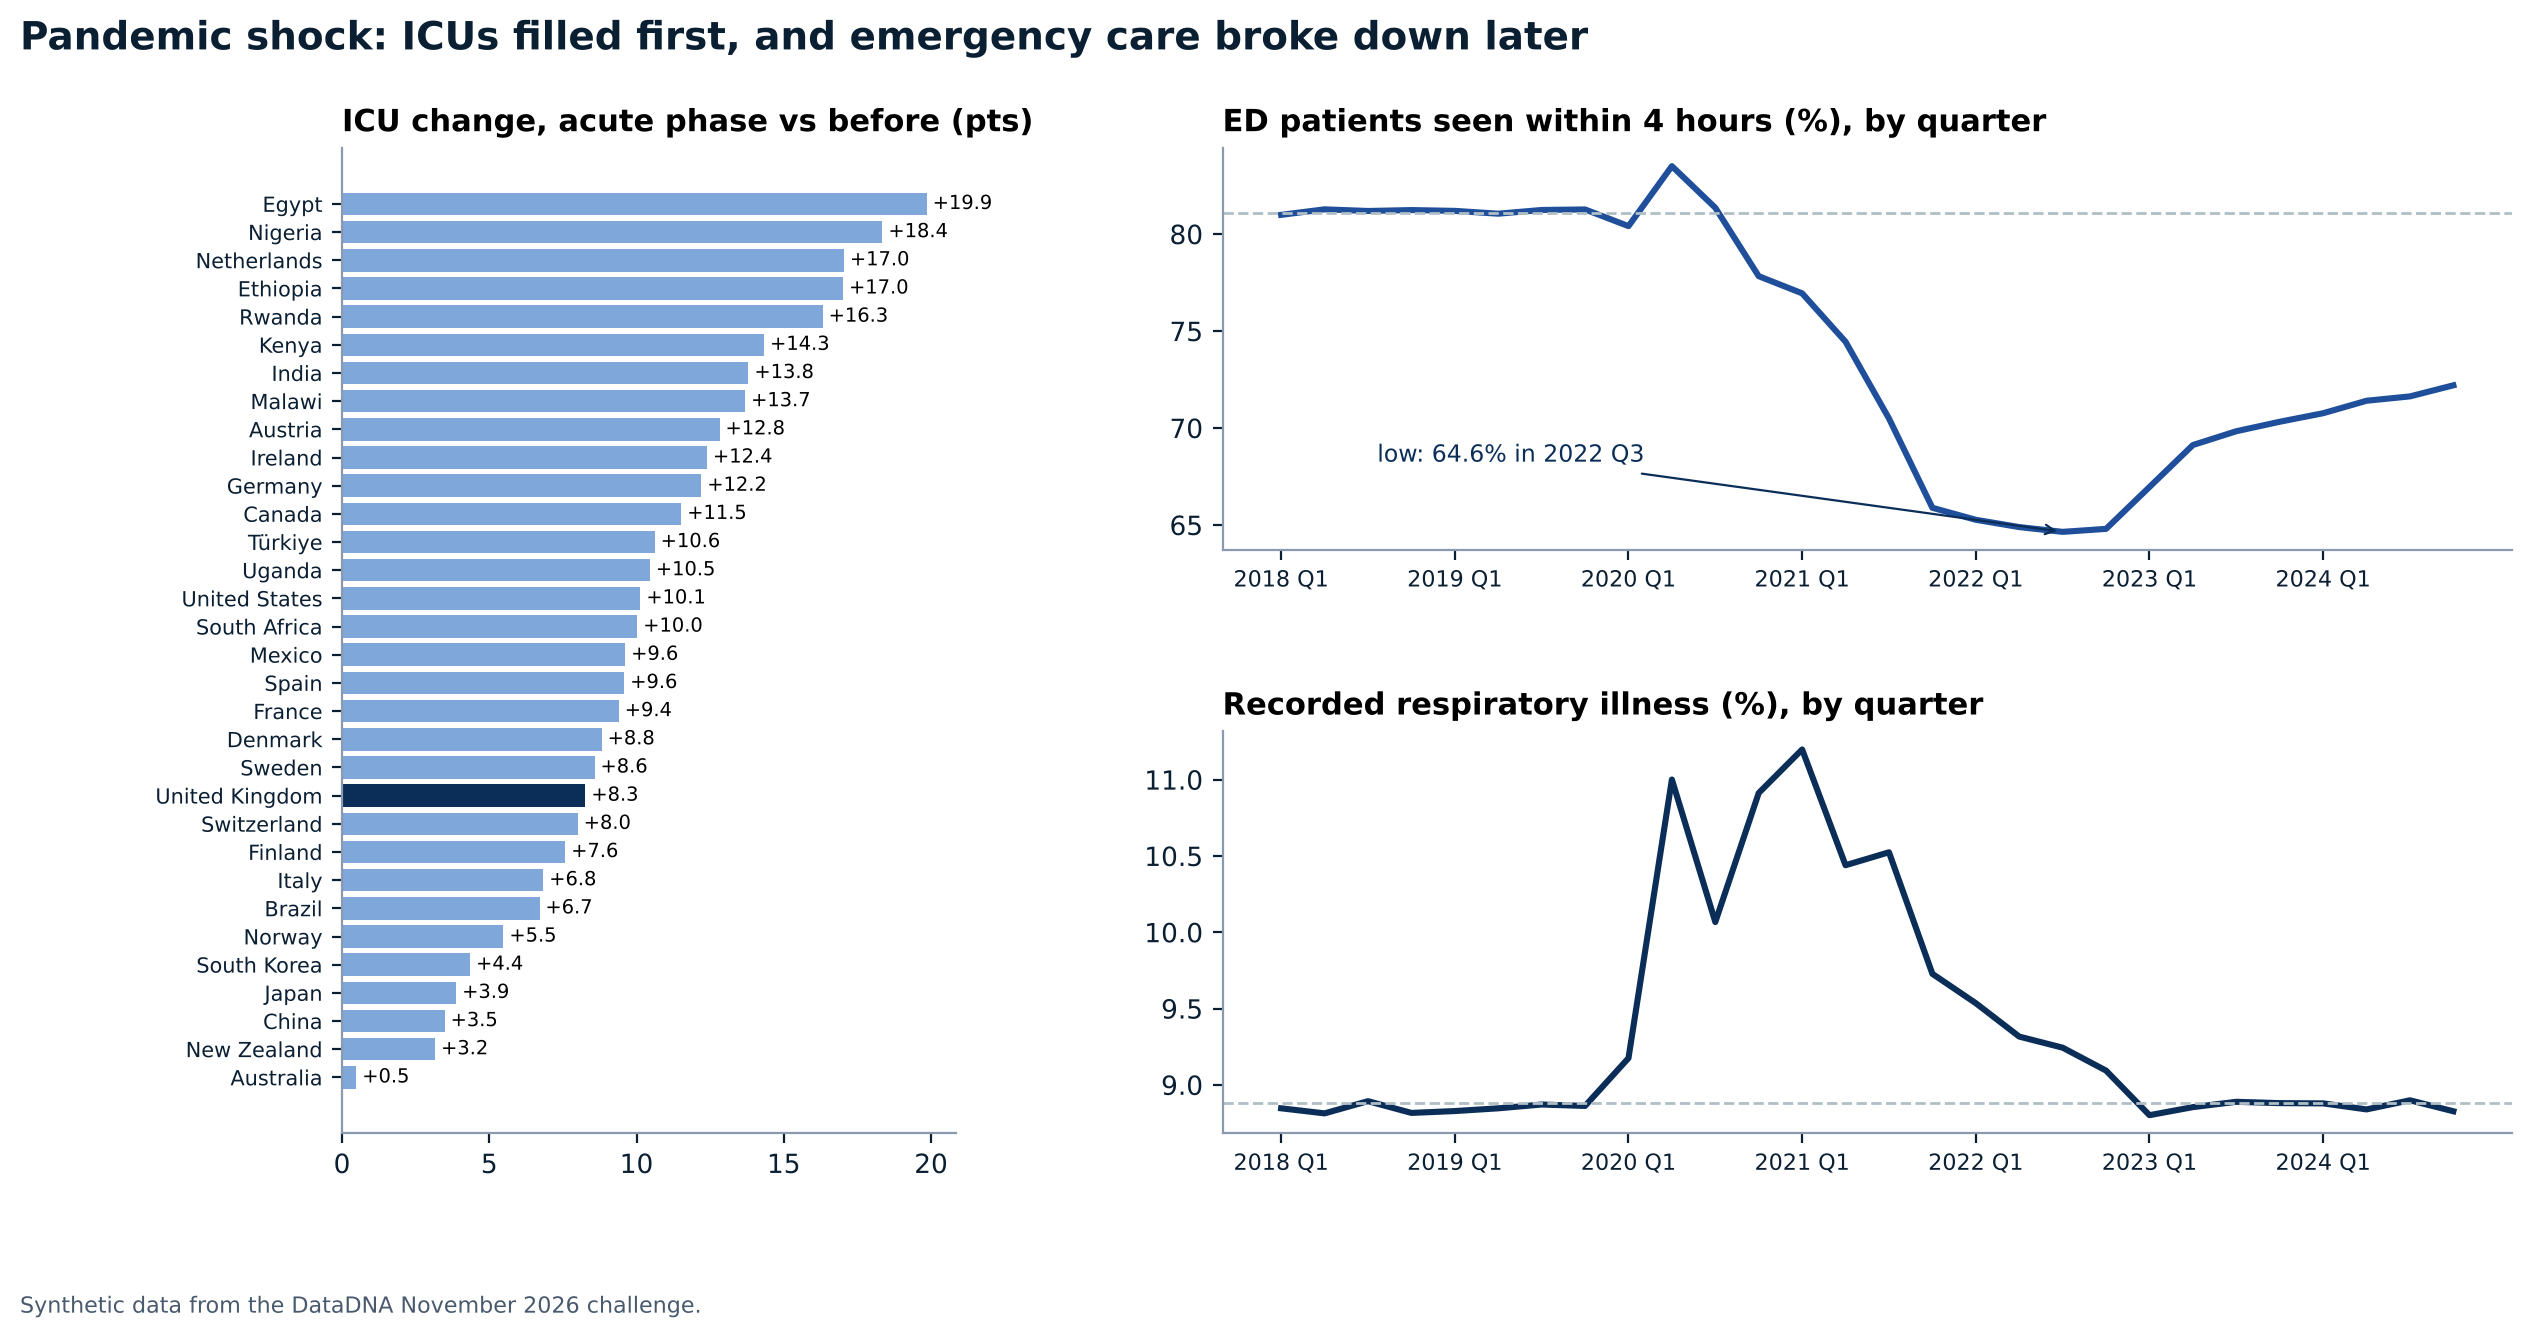

In [6]:
fig = plt.figure(figsize=(14, 6.4))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 2.1], hspace=0.45, wspace=0.28)
ax = fig.add_subplot(gs[:, 0])
ax.barh(icu_by_country.index, icu_by_country.values, color=[DARK if n == "United Kingdom" else LIGHT for n in icu_by_country.index])
ax.set_title("ICU change, acute phase vs before (pts)"); ax.tick_params(axis="y", labelsize=7.5)
for i, v in enumerate(icu_by_country.values): ax.text(v + 0.2, i, f"{v:+.1f}", va="center", fontsize=7)
ax = fig.add_subplot(gs[0, 1])
ax.plot(ed_q.index, ed_q.values, color=MID, lw=2.2); ax.set_title("ED patients seen within 4 hours (%), by quarter")
ax.axhline(ed["Pre-Pandemic"], color=GREY, ls="--", lw=1); ax.annotate(f"low: {ed_q.min():.1f}% in {ed_q.idxmin()}", (ed_q.idxmin(), ed_q.min()),
                                                                       xytext=(0.12, 0.22), textcoords="axes fraction", fontsize=8.5, color=DARK,
                                                                       arrowprops={"arrowstyle": "->", "color": DARK, "lw": 0.8})
ax.set_xticks(ed_q.index[::4]); ax.tick_params(axis="x", labelsize=8)
ax = fig.add_subplot(gs[1, 1])
ax.plot(resp_q.index, resp_q.values, color=DARK, lw=2.2); ax.set_title("Recorded respiratory illness (%), by quarter")
ax.axhline(resp["Pre-Pandemic"], color=GREY, ls="--", lw=1); ax.set_xticks(resp_q.index[::4]); ax.tick_params(axis="x", labelsize=8)
fig.suptitle("Pandemic shock: ICUs filled first, and emergency care broke down later", x=0.01, ha="left", fontweight="bold", fontsize=14, color=INK)
footer(fig); fig.savefig(IMG / f"{PREFIX}01_pandemic_shock.png", dpi=160, bbox_inches="tight"); plt.show()

## 3 · The elective backlog and recovery

In [7]:
wait_year = perf.groupby("year").elective_wait_weeks.mean()
by_cy = perf.pivot_table(index="country_name", columns="year", values="elective_wait_weeks", aggfunc="mean")
ratio_21 = (by_cy[2021] / by_cy[2019]).sort_values()
ratio_24 = (by_cy[2024] / by_cy[2019]).sort_values()
overall = wait_year[2021] / wait_year[2019]
NORDICS = ["Sweden", "Norway", "Denmark", "Finland", "Germany"]
nd = perf[perf.country_name.isin(NORDICS)]
h2 = lambda f: f[(f.year == 2022) & (f.quarter >= 3)].elective_wait_weeks.mean()
nordic_table = pd.DataFrame({n: {"2019": by_cy.loc[n, 2019], "2021": by_cy.loc[n, 2021], "H2 2022": h2(nd[nd.country_name == n])} for n in NORDICS}).T
nordic_table["H2 2022 vs 2019"] = nordic_table["H2 2022"] / nordic_table["2019"]
uk_y, eu_y = perf[UK].groupby("year").elective_wait_weeks.mean(), perf[EU].groupby("year").elective_wait_weeks.mean()
R["Elective wait 2021 vs 2019 (all)"] = overall
R["Countries within ±0.3 of that ratio"] = int((abs(ratio_21 - overall) <= 0.3).sum())
R["Nordics and Germany, H2 2022 vs 2019"] = h2(nd) / nd[nd.year == 2019].elective_wait_weeks.mean()
R["UK wait 2024 vs UK 2019"] = uk_y[2024] / uk_y[2019]
R["UK vs EU wait, 2024"] = uk_y[2024] / eu_y[2024]
R["Highest 2024 vs 2019 outside the UK"] = ratio_24.drop("United Kingdom").max()
nordic_table.round(2)

,2019,2021,H2 2022,H2 2022 vs 2019
Sweden,8.86,14.87,9.23,1.04
Norway,7.75,13.43,8.64,1.11
Denmark,8.78,15.53,9.43,1.07
Finland,8.49,13.11,8.86,1.04
Germany,8.82,22.28,9.50,1.08


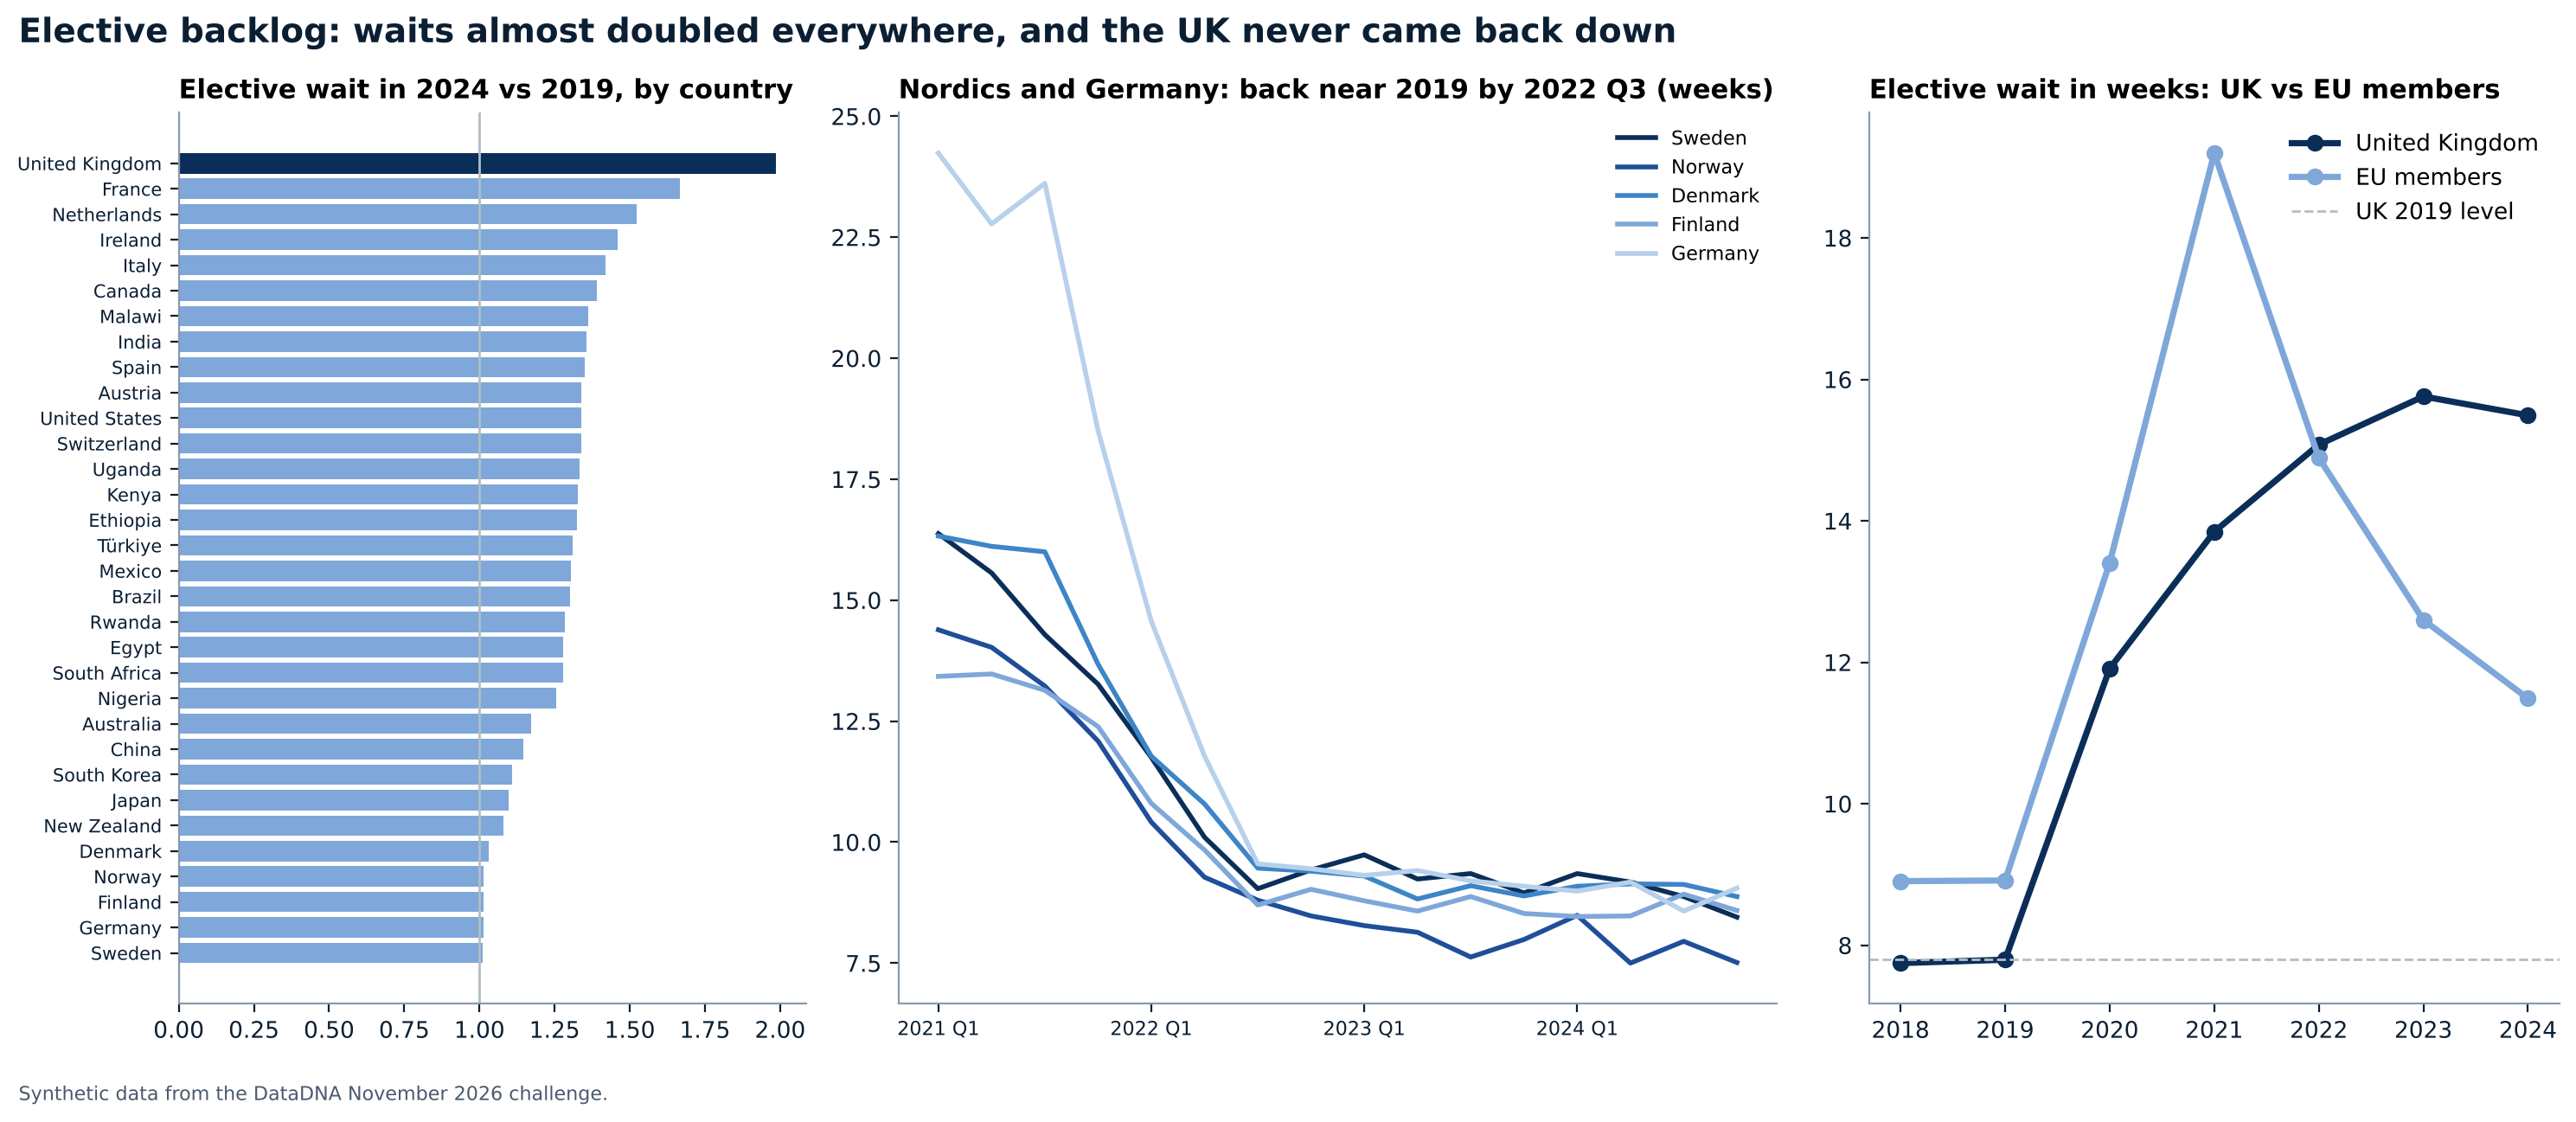

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 6.2), gridspec_kw={"width_ratios": [1, 1.4, 1.1]})
ax = axes[0]
ax.barh(ratio_24.index, ratio_24.values, color=[DARK if n == "United Kingdom" else LIGHT for n in ratio_24.index])
ax.set_title("Elective wait in 2024 vs 2019, by country"); ax.tick_params(axis="y", labelsize=7.5); ax.axvline(1, color=GREY, lw=1)
ax = axes[1]
q = nd[nd.year >= 2021].pivot_table(index="year_quarter", columns="country_name", values="elective_wait_weeks")
for i, n in enumerate(NORDICS): ax.plot(q.index, q[n], color=BLUES[i], lw=2, label=n)
ax.set_title("Nordics and Germany: back near 2019 by 2022 Q3 (weeks)"); ax.set_xticks(q.index[::4]); ax.legend(frameon=False, fontsize=8); ax.tick_params(axis="x", labelsize=8)
ax = axes[2]
ax.plot(uk_y.index, uk_y.values, color=DARK, lw=2.6, marker="o", label="United Kingdom")
ax.plot(eu_y.index, eu_y.values, color=LIGHT, lw=2.6, marker="o", label="EU members")
ax.axhline(uk_y[2019], color=GREY, ls="--", lw=1, label="UK 2019 level")
ax.set_title("Elective wait in weeks: UK vs EU members"); ax.legend(frameon=False)
fig.suptitle("Elective backlog: waits almost doubled everywhere, and the UK never came back down", x=0.01, ha="left", fontweight="bold", fontsize=14, color=INK)
footer(fig); fig.tight_layout(); fig.savefig(IMG / f"{PREFIX}02_elective_recovery.png", dpi=160, bbox_inches="tight"); plt.show()

## 4 · Spending and the workforce

In [9]:
spend = pd.DataFrame({"UK": perf[UK].groupby("year").health_spend_per_capita_usd.mean(), "EU members": perf[EU].groupby("year").health_spend_per_capita_usd.mean()})
spend["UK vs EU"] = spend["UK"] / spend["EU members"]
burn = work.groupby("survey_year").burnout_index.mean()
r_all = work.vacancy_rate_pct.corr(work.burnout_index)
dm = work.assign(b=work.burnout_index - work.groupby("country_id").burnout_index.transform("mean"),
                 v=work.vacancy_rate_pct - work.groupby("country_id").vacancy_rate_pct.transform("mean"))
r_within = (dm.b * dm.v).sum() / np.sqrt((dm.b ** 2).sum() * (dm.v ** 2).sum())
slope_vb = np.polyfit(work.burnout_index, work.vacancy_rate_pct, 1)[0]
uk_b, oh_b = work[UKw].groupby("survey_year").burnout_index.mean(), work[OHIw].groupby("survey_year").burnout_index.mean()
R["UK spend per person (USD)"] = avg(perf[UK], "health_spend_per_capita_usd")
R["EU spend per person (USD)"] = avg(perf[EU], "health_spend_per_capita_usd")
R["UK spend gap to the EU"] = R["UK spend per person (USD)"] / R["EU spend per person (USD)"] - 1
R["Burnout peak year"] = int(burn.idxmax())
R["Burnout index at peak"] = burn.max()
R["Burnout rose every year to the peak"] = bool((burn.loc[:burn.idxmax()].diff().dropna() > 0).all())
R["Burnout and vacancy r (all region years)"] = r_all
R["Burnout and vacancy r (within countries)"] = r_within
R["Vacancy pts per burnout pt"] = slope_vb
R["UK vacancy rate (%)"] = avg(work[UKw], "vacancy_rate_pct")
R["EU vacancy rate (%)"] = avg(work[EUw], "vacancy_rate_pct")
R["UK vs EU vacancy rate"] = R["UK vacancy rate (%)"] / R["EU vacancy rate (%)"]
R["UK burnout change 2022 to 2024 (pts)"] = uk_b[2024] - uk_b[2022]
R["Other high income burnout change 2022 to 2024 (pts)"] = oh_b[2024] - oh_b[2022]
spend.round(3)

,UK,EU members,UK vs EU
year,,,
2018,4295.271,4974.772,0.863
2019,4437.000,5157.006,0.860
2020,4605.125,5335.769,0.863
2021,4773.208,5519.394,0.865
2022,4924.958,5728.572,0.860
2023,5126.146,5917.725,0.866
2024,5306.667,6126.403,0.866


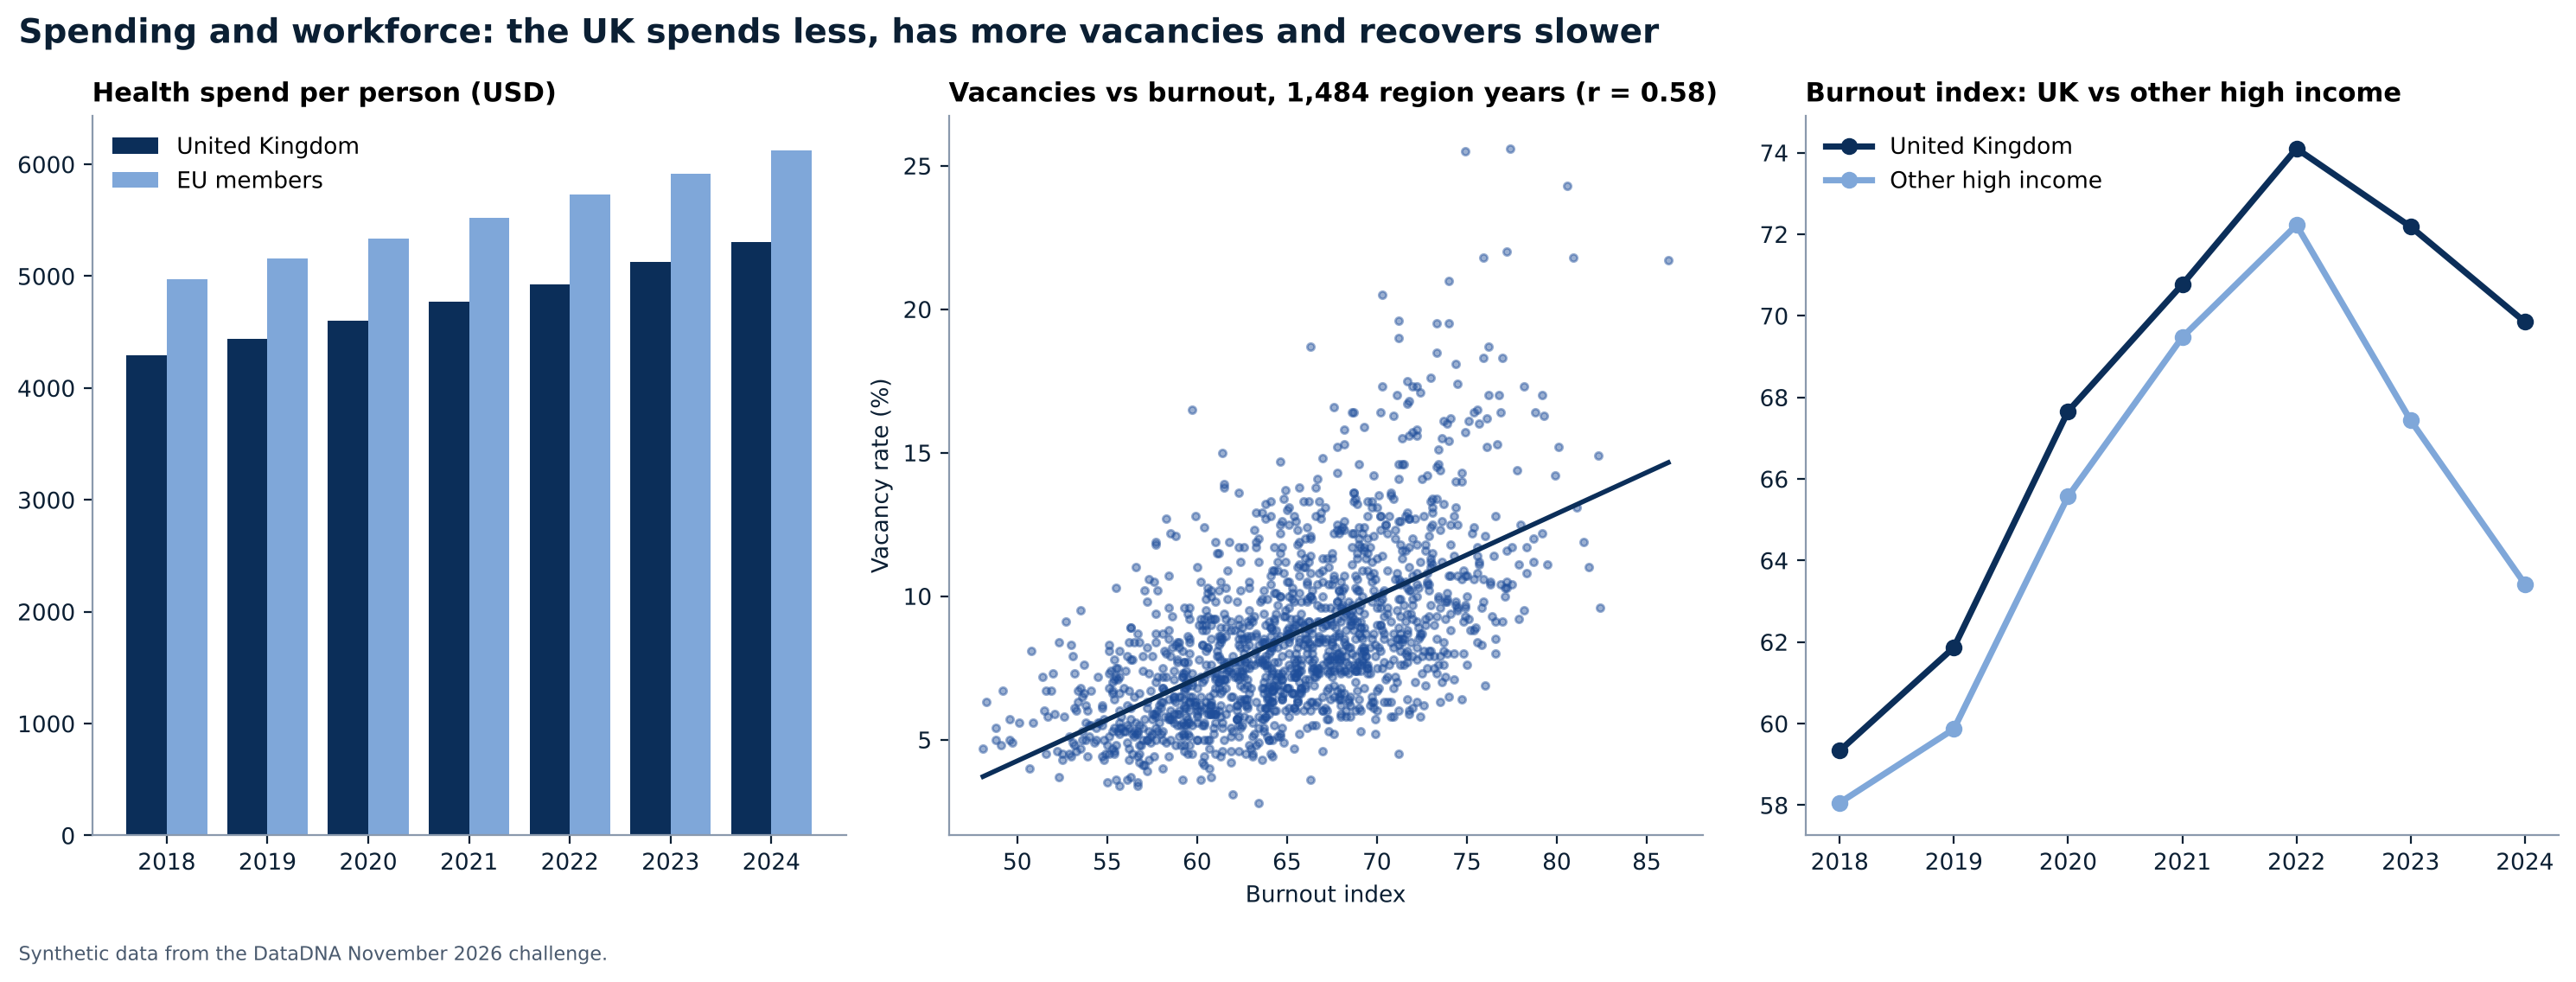

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5.4))
ax = axes[0]; x = np.arange(len(spend))
ax.bar(x - 0.2, spend["UK"], 0.4, color=DARK, label="United Kingdom"); ax.bar(x + 0.2, spend["EU members"], 0.4, color=LIGHT, label="EU members")
ax.set_xticks(x, spend.index); ax.set_title("Health spend per person (USD)"); ax.legend(frameon=False)
ax = axes[1]
ax.scatter(work.burnout_index, work.vacancy_rate_pct, s=9, color=MID, alpha=0.45)
xs = np.linspace(work.burnout_index.min(), work.burnout_index.max(), 50); b0 = np.polyfit(work.burnout_index, work.vacancy_rate_pct, 1)
ax.plot(xs, np.polyval(b0, xs), color=DARK, lw=2)
ax.set_xlabel("Burnout index"); ax.set_ylabel("Vacancy rate (%)"); ax.set_title(f"Vacancies vs burnout, 1,484 region years (r = {r_all:.2f})")
ax = axes[2]
ax.plot(uk_b.index, uk_b.values, color=DARK, lw=2.6, marker="o", label="United Kingdom")
ax.plot(oh_b.index, oh_b.values, color=LIGHT, lw=2.6, marker="o", label="Other high income")
ax.set_title("Burnout index: UK vs other high income"); ax.legend(frameon=False)
fig.suptitle("Spending and workforce: the UK spends less, has more vacancies and recovers slower", x=0.01, ha="left", fontweight="bold", fontsize=14, color=INK)
footer(fig); fig.tight_layout(); fig.savefig(IMG / f"{PREFIX}03_spending_workforce.png", dpi=160, bbox_inches="tight"); plt.show()

## 5 · Long running disease trends

In [11]:
disease = pd.DataFrame({REGION_LABEL[rg]: {"CVD 2018": g[g.year == 2018].cardiovascular_prevalence_pct.mean(), "CVD 2024": g[g.year == 2024].cardiovascular_prevalence_pct.mean(),
                                           "CVD a year": slope(g, "cardiovascular_prevalence_pct"), "Diabetes 2018": g[g.year == 2018].diabetes_prevalence_pct.mean(),
                                           "Diabetes 2024": g[g.year == 2024].diabetes_prevalence_pct.mean(), "Diabetes a year": slope(g, "diabetes_prevalence_pct")}
                        for rg, g in perf.groupby("who_region")}).T.sort_values("CVD a year", ascending=False)
cancer = pd.DataFrame({ig: {"2018": g[g.year == 2018].cancer_incidence_per_100k.mean(), "2024": g[g.year == 2024].cancer_incidence_per_100k.mean(),
                            "per 100k a year": slope(g, "cancer_incidence_per_100k")} for ig, g in perf.groupby("income_group")}).T
cancer["% a year"] = cancer["per 100k a year"] / cancer["2018"]
R["CVD slope, all (pts a year)"] = slope(perf, "cardiovascular_prevalence_pct")
R["Diabetes slope, all (pts a year)"] = slope(perf, "diabetes_prevalence_pct")
R["Recorded cancer, high income (% a year)"] = cancer.loc["High income", "% a year"]
R["Recorded cancer, low income (% a year)"] = cancer.loc["Low income", "% a year"]
disease.round(3)

,CVD 2018,CVD 2024,CVD a year,Diabetes 2018,Diabetes 2024,Diabetes a year
South East Asia,4.450,5.598,0.192,9.718,10.490,0.127
Americas,8.199,9.103,0.151,10.508,11.183,0.112
Europe,10.316,11.212,0.149,6.162,6.853,0.117
Western Pacific,8.837,9.681,0.146,6.994,7.711,0.122
Africa,2.588,3.426,0.140,4.438,5.176,0.124
East Mediterranean,6.064,6.859,0.134,20.818,21.479,0.116


In [12]:
cancer.round(3)

,2018,2024,per 100k a year,% a year
High income,664.931,688.493,3.882,0.006
Low income,77.144,68.450,-1.407,-0.018
Lower middle income,86.264,89.942,0.669,0.008
Upper middle income,239.015,254.260,2.438,0.010


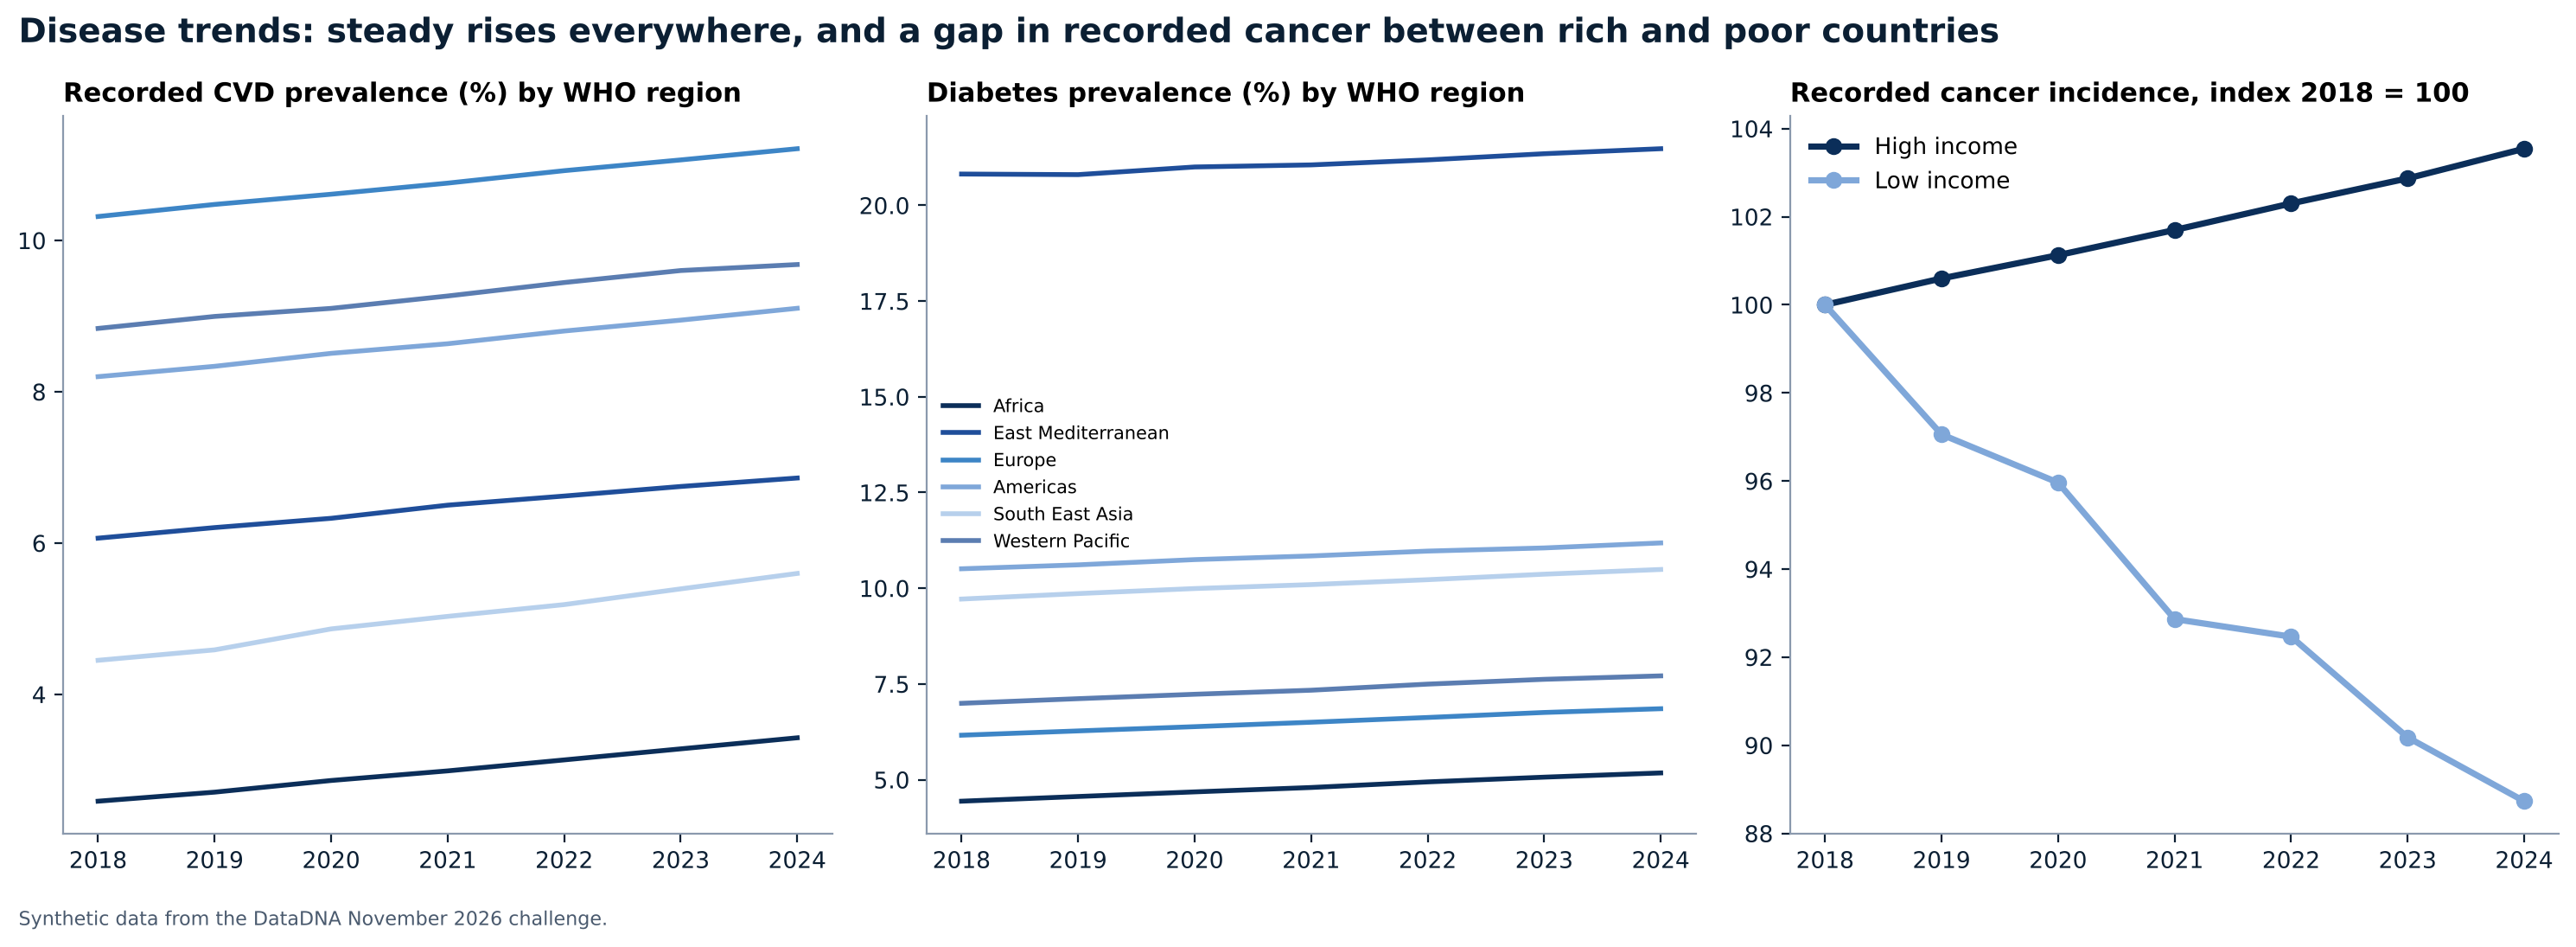

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5.2))
cvd_y = perf.pivot_table(index="year", columns="who_region", values="cardiovascular_prevalence_pct").rename(columns=REGION_LABEL)
dia_y = perf.pivot_table(index="year", columns="who_region", values="diabetes_prevalence_pct").rename(columns=REGION_LABEL)
for i, rg in enumerate(cvd_y.columns):
    axes[0].plot(cvd_y.index, cvd_y[rg], color=BLUES[i % 6], lw=2, label=rg); axes[1].plot(dia_y.index, dia_y[rg], color=BLUES[i % 6], lw=2, label=rg)
axes[0].set_title("Recorded CVD prevalence (%) by WHO region"); axes[1].set_title("Diabetes prevalence (%) by WHO region"); axes[1].legend(frameon=False, fontsize=7.5)
idx = perf.pivot_table(index="year", columns="income_group", values="cancer_incidence_per_100k")
idx = idx / idx.loc[2018] * 100
axes[2].plot(idx.index, idx["High income"], color=DARK, lw=2.6, marker="o", label="High income")
axes[2].plot(idx.index, idx["Low income"], color=LIGHT, lw=2.6, marker="o", label="Low income")
axes[2].set_title("Recorded cancer incidence, index 2018 = 100"); axes[2].legend(frameon=False)
fig.suptitle("Disease trends: steady rises everywhere, and a gap in recorded cancer between rich and poor countries", x=0.01, ha="left", fontweight="bold", fontsize=14, color=INK)
footer(fig); fig.tight_layout(); fig.savefig(IMG / f"{PREFIX}04_disease_trends.png", dpi=160, bbox_inches="tight"); plt.show()

## 6 · A one page Python dashboard
The same story as the Power BI summary page, drawn with matplotlib. Unlike the Power BI bar chart, this one has room for all 32 countries.

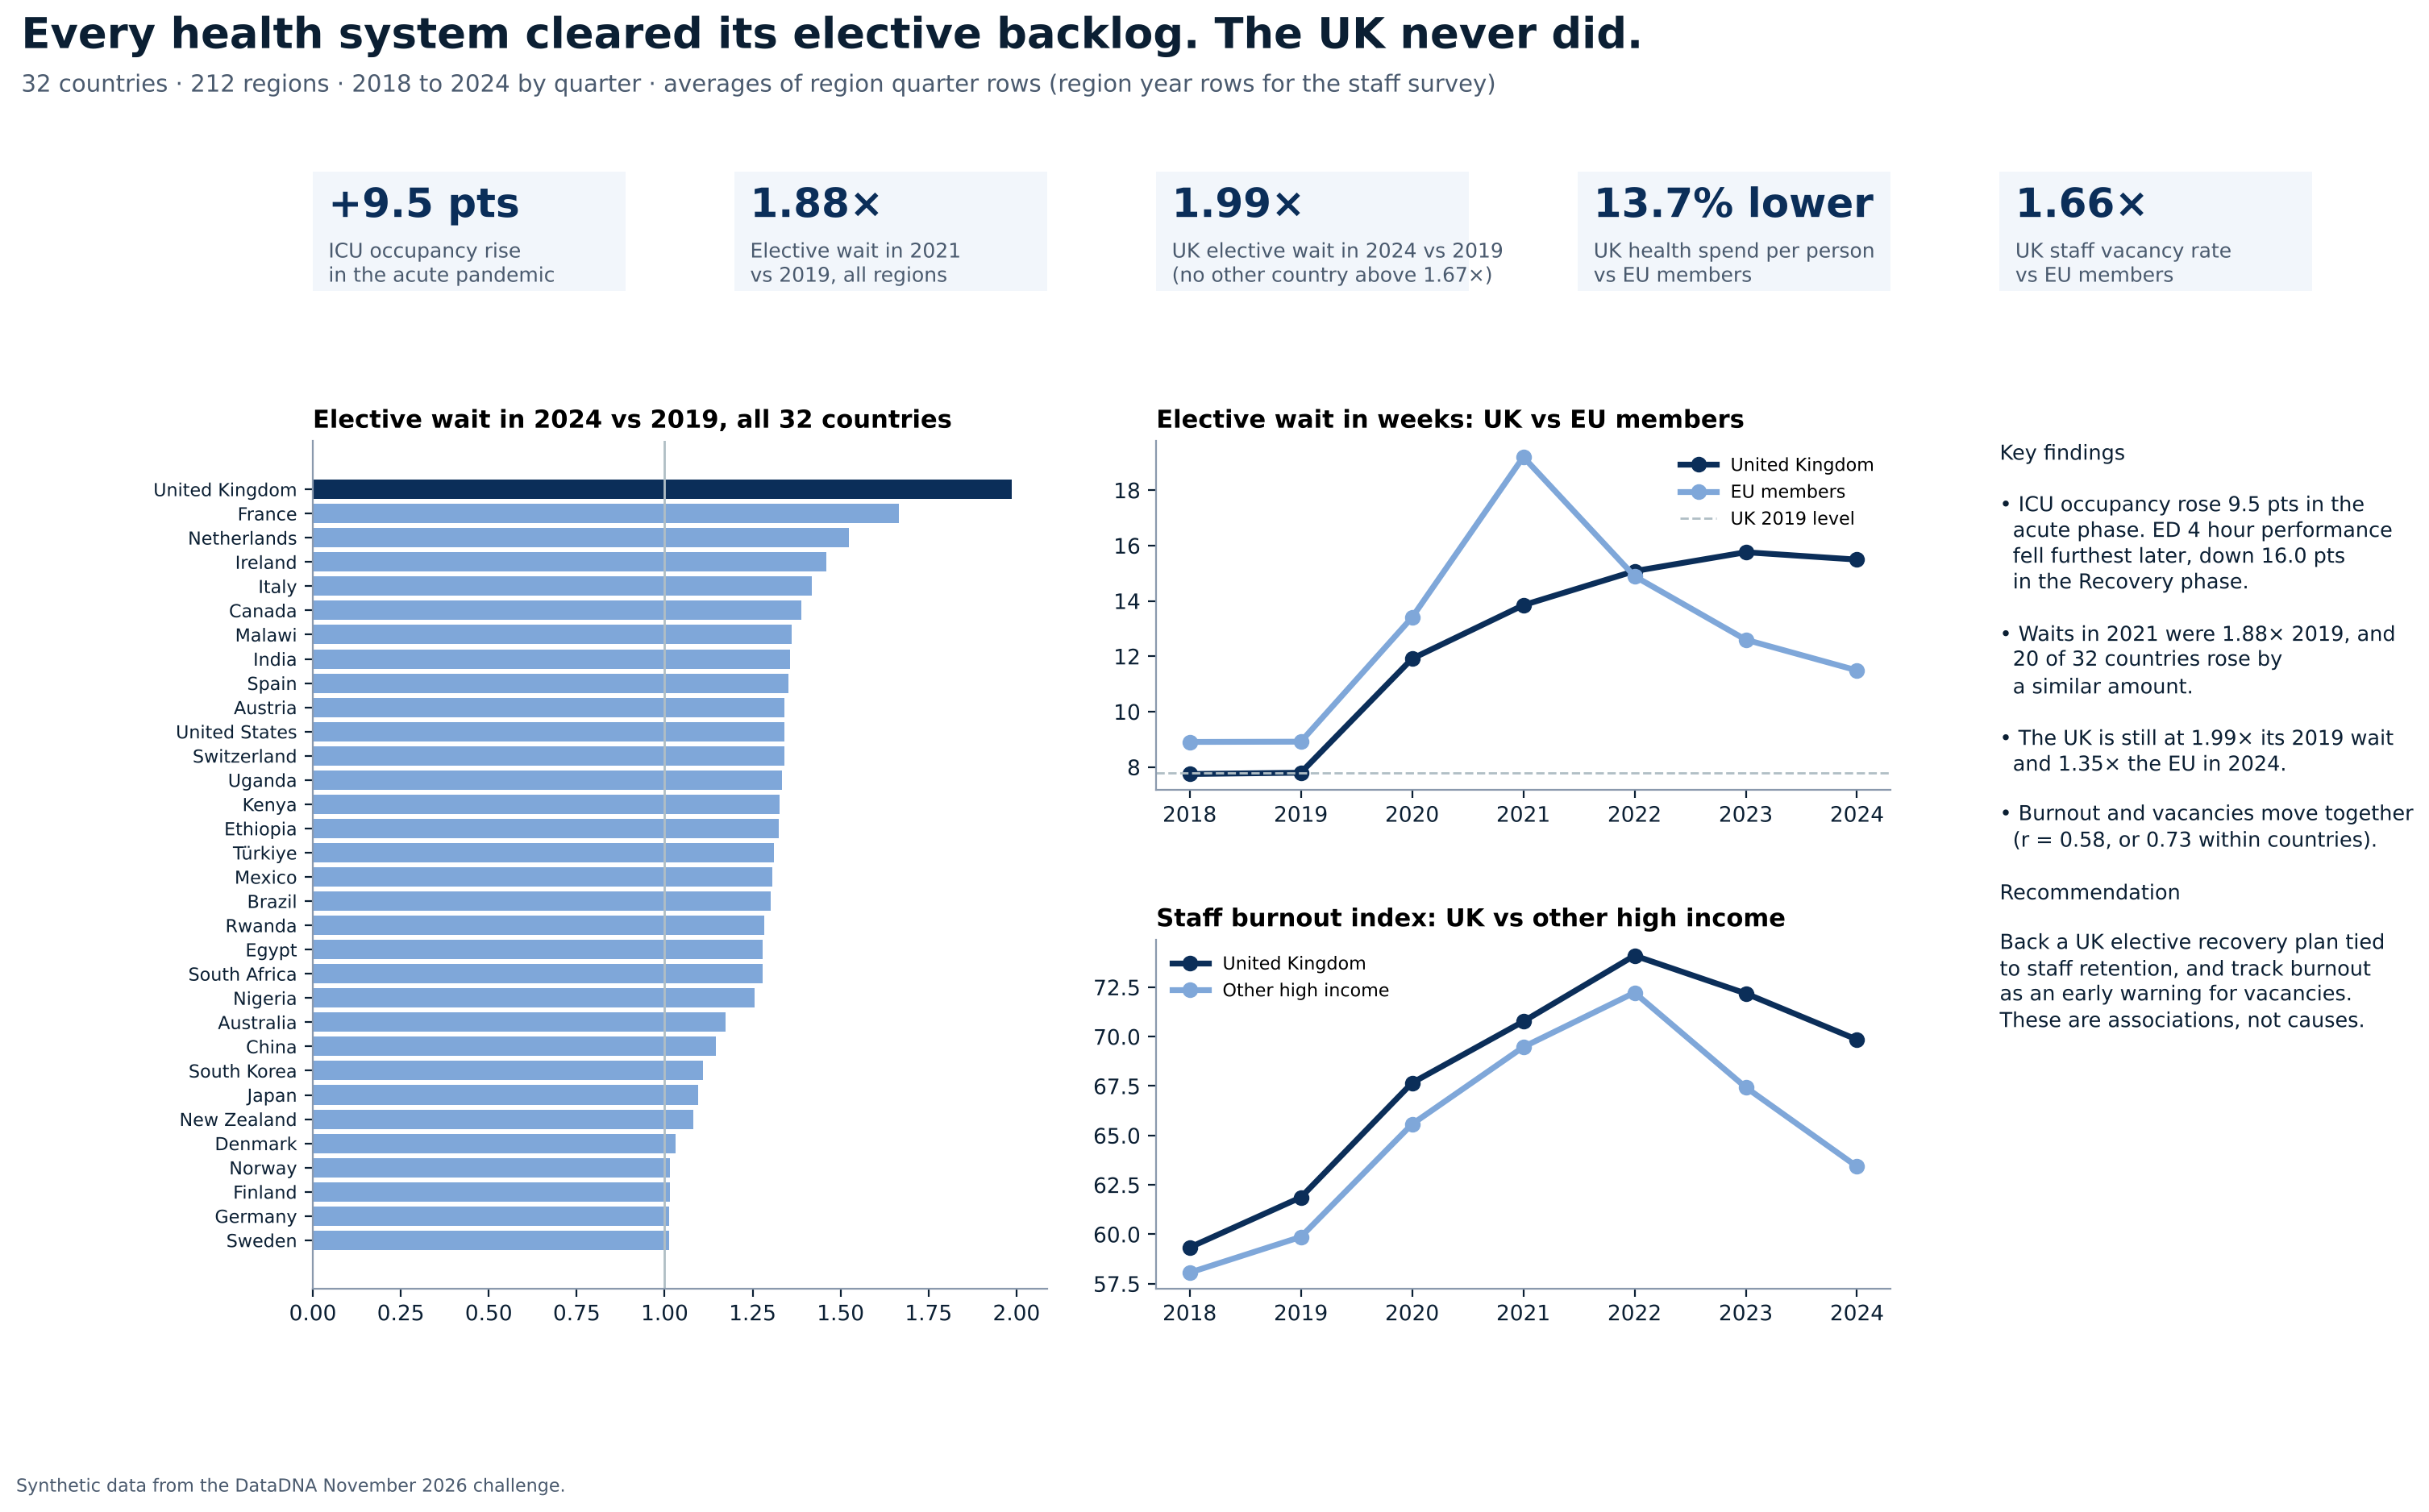

In [14]:
fig = plt.figure(figsize=(16, 9))
gs = fig.add_gridspec(3, 5, height_ratios=[0.55, 1.6, 1.6], hspace=0.55, wspace=0.35)
fig.text(0.012, 0.965, "Every health system cleared its elective backlog. The UK never did.", fontsize=19, fontweight="bold", color=INK)
fig.text(0.012, 0.935, "32 countries · 212 regions · 2018 to 2024 by quarter · averages of region quarter rows (region year rows for the staff survey)", fontsize=10.5, color="#4A5A6E")
kpis = [(f"{R['ICU change, acute vs before (pts)']:+.1f} pts", "ICU occupancy rise\nin the acute pandemic"),
        (f"{R['Elective wait 2021 vs 2019 (all)']:.2f}×", "Elective wait in 2021\nvs 2019, all regions"),
        (f"{R['UK wait 2024 vs UK 2019']:.2f}×", "UK elective wait in 2024 vs 2019\n(no other country above 1.67×)"),
        (f"{abs(R['UK spend gap to the EU']):.1%} lower", "UK health spend per person\nvs EU members"),
        (f"{R['UK vs EU vacancy rate']:.2f}×", "UK staff vacancy rate\nvs EU members")]
for i, (val, lab) in enumerate(kpis):
    ax = fig.add_subplot(gs[0, i]); ax.axis("off")
    ax.add_patch(plt.Rectangle((0, 0), 1, 1, transform=ax.transAxes, color="#F2F6FB", zorder=0))
    ax.text(0.05, 0.62, val, fontsize=18, fontweight="bold", color=DARK, transform=ax.transAxes)
    ax.text(0.05, 0.08, lab, fontsize=9, color="#4A5A6E", transform=ax.transAxes)
ax = fig.add_subplot(gs[1:, 0:2])
ax.barh(ratio_24.index, ratio_24.values, color=[DARK if n == "United Kingdom" else LIGHT for n in ratio_24.index])
ax.set_title("Elective wait in 2024 vs 2019, all 32 countries"); ax.tick_params(axis="y", labelsize=8); ax.axvline(1, color=GREY, lw=1)
ax = fig.add_subplot(gs[1, 2:4])
ax.plot(uk_y.index, uk_y.values, color=DARK, lw=2.6, marker="o", label="United Kingdom"); ax.plot(eu_y.index, eu_y.values, color=LIGHT, lw=2.6, marker="o", label="EU members")
ax.axhline(uk_y[2019], color=GREY, ls="--", lw=1, label="UK 2019 level"); ax.set_title("Elective wait in weeks: UK vs EU members"); ax.legend(frameon=False, fontsize=8)
ax = fig.add_subplot(gs[2, 2:4])
ax.plot(uk_b.index, uk_b.values, color=DARK, lw=2.6, marker="o", label="United Kingdom"); ax.plot(oh_b.index, oh_b.values, color=LIGHT, lw=2.6, marker="o", label="Other high income")
ax.set_title("Staff burnout index: UK vs other high income"); ax.legend(frameon=False, fontsize=8)
ax = fig.add_subplot(gs[1:, 4]); ax.axis("off")
notes = ("Key findings\n\n"
         f"• ICU occupancy rose {R['ICU change, acute vs before (pts)']:.1f} pts in the\n  acute phase. ED 4 hour performance\n  fell furthest later, down {abs(R['ED 4 hour, worst phase vs before (pts)']):.1f} pts\n  in the Recovery phase.\n\n"
         f"• Waits in 2021 were {R['Elective wait 2021 vs 2019 (all)']:.2f}× 2019, and\n  {R['Countries within ±0.3 of that ratio']} of 32 countries rose by\n  a similar amount.\n\n"
         f"• The UK is still at {R['UK wait 2024 vs UK 2019']:.2f}× its 2019 wait\n  and {R['UK vs EU wait, 2024']:.2f}× the EU in 2024.\n\n"
         f"• Burnout and vacancies move together\n  (r = {R['Burnout and vacancy r (all region years)']:.2f}, or {R['Burnout and vacancy r (within countries)']:.2f} within countries).\n\n"
         "Recommendation\n\nBack a UK elective recovery plan tied\nto staff retention, and track burnout\nas an early warning for vacancies.\nThese are associations, not causes.")
ax.text(0, 1, notes, va="top", fontsize=9.2, color=INK, linespacing=1.25)
footer(fig); fig.savefig(IMG / f"{PREFIX}00_dashboard.png", dpi=150, bbox_inches="tight"); plt.show()

## 7 · Reconciliation with the Power BI report
Every headline number in the Power BI report is worked out again above from the raw files. The Power BI column holds the value behind each
figure in the report, and the Python value is rounded to the same number of decimals. Where the report shows a fall as a positive number
under a label like "Drop in ED 4 hour", the value is stored here as a negative number. The last column has to be ✔ on every row.

In [15]:
POWER_BI = {   # value behind each figure on the Power BI report (read from its PDF export), and the decimals it is shown with
    "ICU change, acute vs before (pts)": (9.5, 1),
    "ED 4 hour worst phase": ("Recovery", None),
    "ED 4 hour, worst phase vs before (pts)": (-16.0, 1),      # shown as "Drop in ED 4 hour in that phase: 16.0 pts"
    "ED 4 hour lowest quarter": ("2022 Q3", None),
    "Respiratory, acute vs before (pts)": (1.81, 2),
    "Respiratory, after vs before (pts)": (-0.02, 2),          # shown as "Respiratory illness, drop after pandemic: 0.02 pts"
    "Elective wait 2021 vs 2019 (all)": (1.88, 2),
    "Countries within ±0.3 of that ratio": (20, 0),
    "Nordics and Germany, H2 2022 vs 2019": (1.07, 2),
    "UK wait 2024 vs UK 2019": (1.99, 2),
    "UK vs EU wait, 2024": (1.35, 2),
    "UK spend per person (USD)": (4781, 0),
    "EU spend per person (USD)": (5537, 0),
    "UK spend gap to the EU": (-0.137, 3),                      # shown as "UK spend below EU members: 13.7%"
    "Burnout peak year": (2022, 0),
    "Burnout index at peak": (72.3, 1),
    "Burnout and vacancy r (all region years)": (0.58, 2),
    "UK vs EU vacancy rate": (1.66, 2),
    "CVD slope, all (pts a year)": (0.148, 3),
    "Diabetes slope, all (pts a year)": (0.118, 3),
    "Recorded cancer, high income (% a year)": (0.0058, 4),
    "Recorded cancer, low income (% a year)": (-0.0182, 4),     # shown as "1.82% fall"
}
rows = []
for k, v in R.items():
    pb = POWER_BI.get(k)
    py = v if isinstance(v, str) else (round(float(v), pb[1]) if pb and pb[1] is not None else v)
    if pb and pb[1] == 0: py = int(py)
    rows.append({"measure": k, "Python": py if isinstance(py, str) else (round(py, 4) if not isinstance(v, bool) else v),
                 "Power BI": pb[0] if pb else "", "match": ("✔" if py == pb[0] else "✘") if pb else ""})
recon = pd.DataFrame(rows)
assert set(POWER_BI) <= set(R), set(POWER_BI) - set(R)
print(f"{(recon['match'] == '✔').sum()} of {len(POWER_BI)} Power BI figures reproduced exactly; the rest of the table is supporting detail")
assert (recon["match"] != "✘").all(), recon[recon["match"] == "✘"]
recon

22 of 22 Power BI figures reproduced exactly; the rest of the table is supporting detail


,measure,Python,Power BI,match
0,ICU occupancy before the pandemic (%),72.3091,,
1,"ICU occupancy, acute pandemic (%)",81.8149,,
2,"ICU change, acute vs before (pts)",9.5,9.5,✔
3,ED 4 hour worst phase,Recovery,Recovery,✔
4,"ED 4 hour, worst phase vs before (pts)",-16.0,-16.0,✔
5,ED 4 hour lowest quarter,2022 Q3,2022 Q3,✔
6,ED 4 hour lowest quarter (%),64.642,,
7,"Respiratory, acute vs before (pts)",1.81,1.81,✔
8,"Respiratory, after vs before (pts)",-0.02,-0.02,✔
9,Elective wait 2021 vs 2019 (all),1.88,1.88,✔
